# Охват рекламы в Яндекс Лавке


**Автор:** Долгополова Анна  
**Группа:** БПМ244 (ПМ-14)

На семинаре заполните разделы 1–3 и начните работу с данными. Дома завершите расчёты, выводы и ограничения. Добавляйте ячейки по мере необходимости.

[ТЗ](assignment.md) · [Описание данных](README.md)

Распакуйте архив целиком и сохраняйте ноутбук рядом с тремя CSV и папкой `images`.

## 1. Бизнес-контекст

Зачем бизнесу нужны эти данные?


В Яндекс Лавке реклама может быть размещена в разных местах: на главной в ленте и в поиске. Потенциальная аудитория приложения по разному взаимодействует с разделами приложения и пролисывает ленту на разную глубину.

Рекламной команде необходимо планировать продажи рекламных размещений до конца 2026 года, для чего и важно знать потенциальный охват рекламных мест.

В рамках исследования необходимо оценить среднедневное количество уникальных пользователей, которые потенциально увидят каждый из выбранных рекламных баннеров, при условии, что реклама доступна всем пользователям без ограничений.

Оценка необходима для пяти рекламных мест: 4 банера в ленте и один большой на первом экране страницы поиска

Расчёт необходимо выполнить отдельно для октября, ноября и декабря 2026 года.

## 2. Исследовательский вопрос

Зафиксируйте вопрос, на который вы хотите ответить в рамках этого исследования?


В Яндекс Лавке реклама может быть размещена в разных местах: на главной в ленте и в поиске. Потенциальная аудитория приложения по разному взаимодействует с разделами приложения и пролисывает ленту на разную глубину.

Рекламной команде необходимо планировать продажи рекламных размещений до конца 2026 года, для чего и важно знать потенциальный охват рекламных мест.

В рамках исследования необходимо оценить среднедневное количество уникальных пользователей, которые потенциально увидят каждый из выбранных рекламных баннеров, при условии, что реклама доступна всем пользователям без ограничений.

Оценка необходима для пяти рекламных мест: 4 банера в ленте и один большой на первом экране страницы поиска

Расчёт необходимо выполнить отдельно для октября, ноября и декабря 2026 года.

## 3. Методология

Сначала опишите, каким способом вы ответите на исследовательский вопрос (краткое описание общей логики). Затем уточните детали: какие данные вы будете использовать, и как будете их преобразовывать/агрегировать. Описание должно быть достаточно подробным, чтобы другой аналитик мог воспроизвести ваш подход.


## 3. Методология

Для оценки охвата используем данные о поведении пользователей с 1 по 28 сентября и прогноз среднего DAU на октябрь–декабрь 2026 года

Для рекламных мест в ленте определим
1. какую долю пользователей составляет аудитория ленты
2. какая доля пользователей ленты доходит до каждого рекламного места.

После для каждого места умножим прогнозный DAU на эти доли.

Для баннера на странице поиска определим долю пользователей, которые открывают поиск (тк он находится на первом экране)

Показатели рассчитываем по действиям пользователей из navigation_events.csv и product_impressions.csv, прогноз DAU берем из dau_forecast.csv

## 4. Подготовка данных и реализация расчётов

### 4.1. Загрузка и знакомство с данными

Загрузите три таблицы и изучите их структуру и содержимое.

In [1]:
import pandas as pd

In [2]:
dau = pd.read_csv('dau_forecast.csv')
navigation = pd.read_csv('navigation_events.csv')
impressions = pd.read_csv('product_impressions.csv')

In [3]:
display(dau.head())
print()
print()

display(navigation.head())
print()
print()

display(impressions.head())

,month,avg_dau_plan,avg_dau_actual
0,2026-01,"820,00","811,35"
1,2026-02,"840,00","853,18"
2,2026-03,"875,00","864,52"
3,2026-04,"900,00","913,70"
4,2026-05,"930,00","921,16"


,user_id,timestamp,event_type,section
0,u02703,01.09.2026 07:00:19,app_open,NaN
1,u04000,01.09.2026 07:00:19,app_open,NaN
2,u04000,01.09.2026 07:00:22,section_open,feed
3,u02703,01.09.2026 07:00:29,section_open,search
4,u02703,01.09.2026 07:00:50,section_open,search


,user_id,timestamp,section,product_id,row_number,column
0,u04000,2026-09-01 07:00:24,feed,p0775,"1,0",left
1,u04000,2026-09-01 07:00:24,feed,p0842,"1,0",right
2,u04000,2026-09-01 07:00:28,feed,p1782,"2,0",left
3,u04000,2026-09-01 07:00:28,feed,p1788,"2,0",right
4,u02703,2026-09-01 07:00:31,search,p0723,"1,0",left


In [4]:
dau.info()
print()
print()

navigation.info()
print()
print()

impressions.info()
print()
print()

print(navigation['event_type'].value_counts())
print()
print()

print(navigation['section'].value_counts(dropna=False))
print()
print()

print(impressions['section'].value_counts())
print()
print()

print(sorted(impressions['row_number'].unique()))
print()
print()

print(impressions['column'].value_counts())
print()
print()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   month           12 non-null     str  
 1   avg_dau_plan    12 non-null     str  
 2   avg_dau_actual  12 non-null     str  
dtypes: str(3)
memory usage: 646.0 bytes


<class 'pandas.DataFrame'>
RangeIndex: 91302 entries, 0 to 91301
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     91302 non-null  str  
 1   timestamp   91302 non-null  str  
 2   event_type  91302 non-null  str  
 3   section     54161 non-null  str  
dtypes: str(4)
memory usage: 6.1 MB


<class 'pandas.DataFrame'>
RangeIndex: 455882 entries, 0 to 455881
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   user_id     455882 non-null  str  
 1   timestamp   455882 non-null  str  
 2   section     455882

*Кратко зафиксируйте наблюдения, важные для исследования.*

В навигации есть открытия приложения, переходы в разделы feed и search, в данных о показах товаров есть раздел, номер строки и сторона размещения

данные о навигации и показах содержат информацию за сентябрь 2026 года

пропуски в столбце section таблицы навигации связаны с событиями открытия приложения, для которых раздел не указывается

в row_number представлены номера 1-24

в названиях разделов встречаются различия в регистре и пробелы (feed, FEED и feed с пробелом)

перед расчётами необходимо привести названия разделов к единому виду и проверить типы данных



### 4.2. Подготовка данных

Проверьте, готовы ли данные к расчётам. Выполните необходимые преобразования и объясните принятые решения.

Перед расчётами проверяем, что обе таблицы покрывают все 28 дней. В первой версии ноутбука файл `product_impressions.csv` загрузился не полностью (332 541 строка, данные только до 21.09), а полный файл содержит 455 882 строки за 1–28 сентября.

In [5]:
# 1. Названия разделов: убираем пробелы по краям и приводим к нижнему регистру
navigation['section'] = navigation['section'].str.strip().str.lower()
impressions['section'] = impressions['section'].str.strip().str.lower()

print(navigation['section'].value_counts(dropna=False))
print()
print(impressions['section'].value_counts())

section
NaN        37141
feed       30764
search     13163
catalog    10234
Name: count, dtype: int64

section
feed       329232
catalog     70046
search      56604
Name: count, dtype: int64


In [6]:
# 2. Время: в таблицах разные форматы, поэтому задаём формат явно.
# Если хотя бы одна строка ему не соответствует, pandas выдаст ошибку
navigation['timestamp'] = pd.to_datetime(navigation['timestamp'], format='%d.%m.%Y %H:%M:%S')
impressions['timestamp'] = pd.to_datetime(impressions['timestamp'], format='%Y-%m-%d %H:%M:%S')

navigation['date'] = navigation['timestamp'].dt.normalize()
impressions['date'] = impressions['timestamp'].dt.normalize()

for name, df in [('navigation', navigation), ('impressions', impressions)]:
    print(f"{name}: {df['timestamp'].min()} — {df['timestamp'].max()}, "
          f"дней: {df['date'].nunique()}, строк: {len(df)}")

navigation: 2026-09-01 07:00:19 — 2026-09-28 19:25:33, дней: 28, строк: 91302
impressions: 2026-09-01 07:00:24 — 2026-09-28 19:25:54, дней: 28, строк: 455882


In [7]:
# 3. Номер ряда: строка вида '1,0' -> целое число
impressions['row_number'] = (
    impressions['row_number'].str.replace(',', '.').astype(float).astype(int)
)
print(sorted(impressions['row_number'].unique()))

# 4. DAU: пробел как разделитель тысяч, запятая вместо точки, '—' вместо пропуска
for col in ['avg_dau_plan', 'avg_dau_actual']:
    s = dau[col].str.replace(r'\s', '', regex=True).str.replace(',', '.')
    dau[col] = pd.to_numeric(s.where(s != '—'))

dau

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


,month,avg_dau_plan,avg_dau_actual
0,2026-01,820.0,811.35
1,2026-02,840.0,853.18
2,2026-03,875.0,864.52
3,2026-04,900.0,913.70
4,2026-05,930.0,921.16
5,2026-06,950.0,960.43
6,2026-07,970.0,956.87
7,2026-08,990.0,1006.29
8,2026-09,1030.0,NaN
9,2026-10,1080.0,NaN


In [8]:
# 5. Проверки: полные дубликаты и связь типа события с разделом
print('Полных дубликатов в navigation:', navigation.duplicated().sum())
print('Полных дубликатов в impressions:', impressions.duplicated().sum())
print()
print(pd.crosstab(navigation['event_type'], navigation['section'].fillna('нет раздела')))

Полных дубликатов в navigation: 0
Полных дубликатов в impressions: 0

section       catalog   feed  search  нет раздела
event_type                                       
app_open            0      0       0        37141
section_open    10234  30764   13163            0


- **Разделы.** Привели `section` к нижнему регистру и убрали пробелы: `FEED`, ` feed` и `feed` относятся к одному разделу. Без этого часть посещений и показов потерялась бы при фильтрации.
- **Время.** Перевели `timestamp` в datetime. Форматы в таблицах разные (`дд.мм.гггг` в навигации и `гггг-мм-дд` в показах), поэтому формат задан явно для каждой таблицы. Все строки распознались, и обе таблицы покрывают 28 дней: с 1 по 28 сентября. Добавили столбец `date`, потому что охват считаем по дням.
- **Номер ряда.** `row_number` хранился строкой `'1,0'`. Перевели его в целое число, чтобы сравнивать ряды.
- **DAU.** Числа хранились строками с пробелом между тысячами (`1 030,00`) и запятой, а пропуск был обозначен `—`. Перевели в float, `—` заменили на NaN.
- **Дубликатов нет.** Пропуски в `section` есть только у `app_open`: раздел у открытия приложения не указывается, так что это не ошибка. Удалять ничего не нужно.

### 4.3. Расчёты

Реализуйте описанную методологию. Сопровождайте расчёты пояснениями и проверьте полученные результаты.

**Шаг 1. Где находятся баннеры.** По схеме ленты баннер занимает одну из двух ячеек в рядах 3 (справа), 6 (слева), 12 (слева) и 15 (справа). Проверим, что нумерация рядов в данных совпадает со схемой: в этих рядах показы карточек должны быть только в одной колонке.

In [9]:
feed = impressions[impressions['section'] == 'feed']
pd.crosstab(feed['row_number'], feed['column'])

column,left,right
row_number,,
1,29596,29596
2,23668,23668
3,19191,0
4,15733,15733
5,13107,13107
6,0,11049
7,9328,9328
8,8004,8004
9,6934,6934


В рядах 3, 6, 12 и 15 одна колонка пустая, и это ровно те ячейки, где по схеме стоят баннеры. В остальных рядах заполнены обе колонки. Значит, в данных ряды пронумерованы вместе с рядами баннеров, а баннер появляется на экране одновременно с соседней карточкой. Поэтому будем считать, что пользователь **увидел баннер в ряду r, если ему показали карточку из ряда r**.

**Шаг 2. Глубина просмотра.** Лента непрерывная: если пользователь увидел ряд r, он прокрутил и все ряды выше. Проверим, что в данных нет пропусков рядов. Тогда для каждого пользователя за день достаточно знать самый дальний увиденный ряд.

In [10]:
depth = feed.groupby(['date', 'user_id'])['row_number'].agg(['min', 'max', 'nunique'])
print('Пользователе-дней с показами в ленте:', len(depth))
print('Просмотр начинается не с 1-го ряда:', (depth['min'] != 1).sum())
print('Есть пропуски рядов:', (depth['max'] != depth['nunique']).sum())

depth = depth['max'].rename('max_row').reset_index()

Пользователе-дней с показами в ленте: 19054
Просмотр начинается не с 1-го ряда: 0
Есть пропуски рядов: 0


**Шаг 3. DAU в выборке.** Активный пользователь дня — тот, у кого в этот день есть `app_open`. Сравним средний DAU выборки с планом на сентябрь и проверим, насколько точно план совпадал с фактом в предыдущие месяцы.

In [11]:
app_open = navigation[navigation['event_type'] == 'app_open']
daily = app_open.groupby('date')['user_id'].nunique().rename('dau').to_frame()

print('Уникальных пользователей в день по всем событиям совпадает с app_open:',
      navigation.groupby('date')['user_id'].nunique().equals(daily['dau']))
print('Средний DAU в выборке:', round(daily['dau'].mean(), 1))
print('План DAU на сентябрь:', dau.loc[dau['month'] == '2026-09', 'avg_dau_plan'].iloc[0])

hist = dau.dropna(subset=['avg_dau_actual'])
print()
print('Отклонение факта от плана, %:')
print((hist.set_index('month')['avg_dau_actual'] / hist.set_index('month')['avg_dau_plan'] - 1)
      .mul(100).round(1).to_string())

Уникальных пользователей в день по всем событиям совпадает с app_open: True
Средний DAU в выборке: 1017.2
План DAU на сентябрь: 1030.0

Отклонение факта от плана, %:
month
2026-01   -1.1
2026-02    1.6
2026-03   -1.2
2026-04    1.5
2026-05   -1.0
2026-06    1.1
2026-07   -1.4
2026-08    1.6


Средний DAU выборки (≈1017) отличается от плана на сентябрь (1030) примерно на 1%. Это укладывается в обычную точность плана: с января по август факт отклонялся от плана не больше чем на ±1,7%. Значит, прогноз и данные о поведении согласованы и их можно использовать вместе.

**Шаг 4. Аудитория ленты и доходимость до баннеров.**

In [12]:
sections = navigation[navigation['event_type'] == 'section_open']
feed_users = sections.loc[sections['section'] == 'feed', ['date', 'user_id']].drop_duplicates()
daily['feed_users'] = feed_users.groupby('date')['user_id'].nunique()

# у всех, кто видел карточки в ленте, должно быть открытие ленты в этот день
check = depth.merge(feed_users, on=['date', 'user_id'], how='left', indicator=True)
print('Показы в ленте без открытия ленты:', (check['_merge'] == 'left_only').sum())
print('Открыли ленту, но не увидели ни одной карточки:', len(feed_users) - len(depth),
      f'({1 - len(depth) / len(feed_users):.1%} посещений ленты)')

banners = {
    'Сырная шпаргалка (ряд 3)': 3,
    'Monterra (ряд 6)': 6,
    'Манго (ряд 12)': 12,
    'Идеи (ряд 15)': 15,
}
for name, row in banners.items():
    daily[name] = depth[depth['max_row'] >= row].groupby('date')['user_id'].nunique()

Показы в ленте без открытия ленты: 0
Открыли ленту, но не увидели ни одной карточки: 1135 (5.6% посещений ленты)


**Шаг 5. Баннер в поиске.** Баннер стоит на первом экране поиска, поэтому его видит каждый, кто открыл раздел. Считаем охват по открытиям поиска из `navigation`, а **не** по показам товаров. На стартовом экране поиска товаров ещё нет, они появляются только после запроса, поэтому показы товаров занизили бы охват баннера.

In [13]:
search_users = sections.loc[sections['section'] == 'search', ['date', 'user_id']].drop_duplicates()
daily['Поиск (первый экран)'] = search_users.groupby('date')['user_id'].nunique()

search_imp_users = (impressions.loc[impressions['section'] == 'search', ['date', 'user_id']]
                    .drop_duplicates())
print('Открывали поиск (пользователе-дней):', len(search_users))
print('Видели товары в поиске:', len(search_imp_users))
print('Открыли поиск, но не увидели товаров:', len(search_users) - len(search_imp_users),
      f'({1 - len(search_imp_users) / len(search_users):.1%})')

print()
print('Пропусков в дневной таблице:', daily.isna().sum().sum())
daily.head(7)

Открывали поиск (пользователе-дней): 10606
Видели товары в поиске: 8112
Открыли поиск, но не увидели товаров: 2494 (23.5%)

Пропусков в дневной таблице: 0


,dau,feed_users,Сырная шпаргалка (ряд 3),Monterra (ряд 6),Манго (ряд 12),Идеи (ряд 15),Поиск (первый экран)
date,,,,,,,
2026-09-01,962,679,452,280,121,82,373
2026-09-02,997,693,477,293,141,103,369
2026-09-03,1008,725,494,315,134,95,393
2026-09-04,938,672,452,288,123,89,351
2026-09-05,1145,818,579,356,183,132,419
2026-09-06,1123,800,558,373,187,139,403
2026-09-07,977,716,510,301,137,103,351


**Шаг 6. Доли от DAU.** Для каждого места делим средний дневной охват на средний DAU за 28 дней. Для ленты раскладываем долю так, как описано в методологии: доля аудитории ленты × доля пользователей ленты, дошедших до места. 28 дней — это ровно 4 недели, поэтому каждый день недели входит в среднее одинаковое число раз.

In [14]:
places = list(banners) + ['Поиск (первый экран)']

feed_share = daily['feed_users'].mean() / daily['dau'].mean()
depth_share = daily[list(banners)].mean() / daily['feed_users'].mean()
search_share = daily['Поиск (первый экран)'].mean() / daily['dau'].mean()

share = pd.concat([feed_share * depth_share, pd.Series({'Поиск (первый экран)': search_share})])

shares_daily = daily[places].div(daily['dau'], axis=0)

print(f'Доля аудитории ленты от DAU: {feed_share:.1%}')
pd.DataFrame({
    'Доля пользователей ленты, дошедших до места, %': (depth_share * 100).round(1),
    'Доля от DAU, %': (share * 100).round(1),
    'Ст. отклонение дневной доли, п.п.': (shares_daily.std() * 100).round(1),
}).reindex(places)

Доля аудитории ленты от DAU: 70.9%


,"Доля пользователей ленты, дошедших до места, %","Доля от DAU, %","Ст. отклонение дневной доли, п.п."
Сырная шпаргалка (ряд 3),69.2,49.0,1.7
Monterra (ряд 6),43.4,30.8,1.5
Манго (ряд 12),20.0,14.1,1.5
Идеи (ряд 15),14.3,10.2,1.4
Поиск (первый экран),NaN,37.2,1.7


Проверим, что доли стабильны в течение сентября и не сильно зависят от дня недели. Иначе среднее за месяц нельзя было бы переносить на октябрь–декабрь.

In [15]:
stab = shares_daily.mul(100)
by_week = stab.groupby((stab.index.day - 1) // 7 + 1).mean().round(1)
by_week.index = [f'неделя {i}' for i in by_week.index]
by_daytype = stab.groupby(stab.index.dayofweek >= 5).mean().round(1)
by_daytype.index = by_daytype.index.map({False: 'будни', True: 'выходные'})

pd.concat([by_week, by_daytype])

,Сырная шпаргалка (ряд 3),Monterra (ряд 6),Манго (ряд 12),Идеи (ряд 15),Поиск (первый экран)
неделя 1,49.2,30.8,14.3,10.3,37.2
неделя 2,48.4,30.5,14.0,10.0,38.5
неделя 3,48.3,30.1,13.6,9.7,37.7
неделя 4,49.9,31.5,14.4,10.4,35.6
будни,48.6,30.2,13.4,9.5,37.4
выходные,49.9,32.1,15.8,11.7,36.9


- Нумерация рядов в данных совпадает со схемой ленты, баннеры стоят в рядах 3, 6, 12 и 15. Пропусков в прокрутке нет, поэтому «увидел баннер» = «самый дальний увиденный ряд ≥ ряда баннера».
- Все показы в ленте и поиске относятся к пользователям, которые в тот же день открывали этот раздел. Таблицы согласованы.
- Около 5,6% посещений ленты проходят без показа хотя бы одной карточки. Таких пользователей мы не считаем увидевшими баннер.
- Почти четверть открытий поиска проходит без показа товаров. Поэтому охват баннера в поиске считаем по открытиям раздела, а не по показам товаров.
- Доли от DAU стабильны: по неделям они меняются в пределах 1–3 п.п., дневное стандартное отклонение 1,4–1,7 п.п. По выходным до глубоких рядов доходит чуть больше людей (например, до «Идей» 11,7% против 9,5% в будни). В следующем разделе проверим, влияет ли это на месячные оценки.

### 4.4. Результаты

Представьте оценку среднедневного охвата каждого выбранного места по месяцам — с октября по декабрь. Выберите понятный способ представления результатов и укажите единицы измерения.

In [16]:
months = {'2026-10': 'Октябрь', '2026-11': 'Ноябрь', '2026-12': 'Декабрь'}
forecast = dau.set_index('month').loc[list(months), 'avg_dau_plan']

result = pd.DataFrame({'Доля от DAU, %': (share * 100).round(1)})
for m, label in months.items():
    result[label] = (share * forecast[m]).round().astype(int)
result.index.name = 'Рекламное место'

print('Прогноз среднего DAU:', ', '.join(f'{months[m]} — {v:.0f}' for m, v in forecast.items()))
print('Среднедневной охват, уникальных пользователей в день:')
result

Прогноз среднего DAU: Октябрь — 1080, Ноябрь — 1160, Декабрь — 1320
Среднедневной охват, уникальных пользователей в день:


,"Доля от DAU, %",Октябрь,Ноябрь,Декабрь
Рекламное место,,,,
Сырная шпаргалка (ряд 3),49.0,529,569,647
Monterra (ряд 6),30.8,332,357,406
Манго (ряд 12),14.1,153,164,187
Идеи (ряд 15),10.2,110,118,134
Поиск (первый экран),37.2,402,432,492


Проверка устойчивости: в месяцах разное число будних и выходных дней (например, в октябре 5 суббот, а в декабре 4). Пересчитаем охват с долями, взятыми отдельно для каждого дня недели, и взвесим их по календарю месяца. Ниже разница с основной оценкой в пользователях:

In [17]:
dow = daily.index.dayofweek
share_by_dow = daily.groupby(dow)[places].mean().div(daily.groupby(dow)['dau'].mean(), axis=0)

alt = {}
for m, label in months.items():
    days = pd.date_range(f'{m}-01', periods=pd.Period(m).days_in_month)
    weights = pd.Series(days.dayofweek).value_counts(normalize=True)
    alt[label] = (share_by_dow.mul(weights, axis=0).sum() * forecast[m]).round().astype(int)

pd.DataFrame(alt) - result[list(months.values())]

,Октябрь,Ноябрь,Декабрь
Сырная шпаргалка (ряд 3),0,0,-1
Monterra (ряд 6),0,0,-1
Манго (ряд 12),-1,0,-3
Идеи (ряд 15),-1,0,-2
Поиск (первый экран),0,0,0


Разница не больше 3 пользователей (меньше 2%). Календарь месяца на оценку почти не влияет, поэтому оставляем простой вариант.

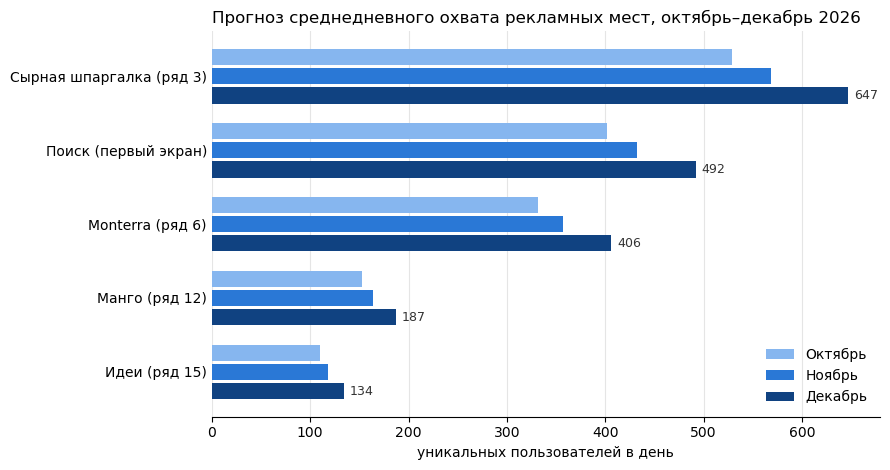

In [18]:
import matplotlib.pyplot as plt

order = result.sort_values('Декабрь', ascending=False)
colors = ['#86b6ef', '#2a78d6', '#104281']  # октябрь -> декабрь: от светлого к тёмному
h = 0.26

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, (label, color) in enumerate(zip(months.values(), colors)):
    y = [p + (i - 1) * h for p in range(len(order))]
    ax.barh(y, order[label], height=h - 0.04, color=color, label=label)
    if label == 'Декабрь':
        for yi, v in zip(y, order[label]):
            ax.text(v + 6, yi, str(v), va='center', fontsize=9, color='#333333')

ax.set_yticks(range(len(order)))
ax.set_yticklabels(order.index)
ax.invert_yaxis()
ax.set_xlabel('уникальных пользователей в день')
ax.set_title('Прогноз среднедневного охвата рекламных мест, октябрь–декабрь 2026', loc='left')
ax.grid(axis='x', color='#e5e5e5')
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

## 5. Вывод

Ответьте на исследовательский вопрос, опираясь на результаты. Сформулируйте ответ так, чтобы рекламная команда могла использовать его при планировании.

Если реклама доступна всем пользователям без таргетинга, рекламные места дадут следующий **среднедневной охват (уникальных пользователей в день)**:

| Рекламное место | Доля от DAU | Октябрь | Ноябрь | Декабрь |
|---|---|---|---|---|
| «Сырная шпаргалка», лента, ряд 3 | 49,0% | 529 | 569 | 647 |
| Баннер на первом экране поиска | 37,2% | 402 | 432 | 492 |
| Monterra, лента, ряд 6 | 30,8% | 332 | 357 | 406 |
| «Манго», лента, ряд 12 | 14,1% | 153 | 164 | 187 |
| «Идеи», лента, ряд 15 | 10,2% | 110 | 118 | 134 |

- **Больше всего охвата даёт место в 3-м ряду ленты:** его видит примерно половина пользователей, активных за день.
- **Баннер в поиске на втором месте** (≈37% DAU) и охватывает больше, чем Monterra в 6-м ряду. Поиск открывает меньше людей, чем ленту, но баннер стоит на первом экране и достаётся каждому, кто открыл раздел.
- **Чем глубже место в ленте, тем меньше охват:** 6-й ряд ≈31% DAU, 12-й ≈14%, 15-й ≈10%. «Идеи» видит в 5 раз меньше людей, чем 3-й ряд. Это стоит учитывать в цене размещения или продавать глубокие места пакетом.
- **Охват растёт вместе с DAU:** в декабре он на 22% выше, чем в октябре, потому что прогноз DAU растёт с 1080 до 1320.
- **Охваты разных мест нельзя складывать:** одни и те же люди видят несколько баннеров. Среднедневной охват нельзя и умножать на число дней, чтобы получить охват уникальных пользователей за месяц.

## 6. Ограничения

Что ограничивает применимость ваших оценок? Объясните, как это влияет на интерпретацию и использование результатов.

- **Поведение перенесено с сентября.** Доли взяты за 1–28 сентября, и мы предполагаем, что в октябре–декабре люди будут так же часто открывать ленту и поиск и так же глубоко прокручивать ленту. Сильнее всего это допущение может нарушиться в декабре: прогноз DAU растёт на 14% к ноябрю (новогодний сезон, новые пользователи), а новая аудитория и предпраздничные покупки могут менять глубину просмотра. Оценку на декабрь стоит считать наименее надёжной.
- **Прогноз DAU — это план.** С января по август факт отклонялся от плана на величину до ±1,7%. На столько же может ошибиться и оценка охвата, даже если поведение не изменится.
- **Это среднее за день, а не охват конкретного дня.** Дневная доля колеблется на 1,4–1,7 п.п. По выходным до глубоких рядов доходит больше людей, чем в будни (до 15-го ряда 11,7% против 9,5% DAU), поэтому в отдельные дни охват будет заметно отличаться от среднего.
- **«Увидел» означает «место появилось на экране».** Это потенциальный охват, верхняя граница: заметил ли человек баннер, данные не показывают. Схема ленты условная, поэтому мы предполагаем, что баннер виден тогда же, когда соседняя карточка в его ряду.
- **Посещения без показов.** 5,6% посещений ленты проходят без показа хотя бы одной карточки, и мы не считаем этих пользователей увидевшими баннер. Если на самом деле первый экран у них отображался, охват верхних мест немного занижен.
- **Баннер в поиске виден всем, кто открыл раздел.** Это условие кейса. Если часть пользователей попадает сразу в результаты поиска, минуя стартовый экран, реальный охват будет ниже.
- **Без ограничений показа.** Оценка не учитывает таргетинг, частотные ограничения и то, что сама реклама может менять поведение пользователей (например, глубину прокрутки).
- **Данные синтетические** и покрывают только один месяц, поэтому сезонность по ним оценить нельзя.